# Benchmark HDFS vs Apache Ozone — Prestazioni e storage

Quattro dimensioni (10 KiB, 50 MiB, 250 MiB e 1 GiB), **3 ripetizioni per sistema**, con nomi remoti differenti per ogni upload, mantenendo lo stesso contenuto per dimensione.

Per ciascuna ripetizione misuriamo lo storage **prima e dopo** l’upload (fuori dal cronometro), poi scarichiamo e verifichiamo SHA-256. Gli oggetti restano memorizzati fino alla fine; non lanciare altri benchmark contemporaneamente.

In [1]:
from src.benchmark import BenchmarkConfig, run_benchmark, plot_storage_results
from src.storage_analysis import snapshot

config = BenchmarkConfig(repetitions=3, clean_remote=False, settle_seconds=2.0)
print(config)
print("Volumi accessibili:", ", ".join(snapshot()))

BenchmarkConfig(repetitions=3, results_dir=PosixPath('/home/jovyan/work/results'), hdfs_prefix='/benchmark/performance', ozone_prefix='performance', ozone_bucket='asdbd-benchmark', clean_remote=False, settle_seconds=2.0)
Volumi accessibili: hdfs_name, hdfs_dn1, hdfs_dn2, hdfs_dn3, ozone_scm, ozone_om, ozone_dn, ozone_recon


## Esecuzione integrale e ripresa

Ogni upload usa una chiave unica. Le rilevazioni sono salvate dopo la verifica del download.

**Attenzione:** se l’esecuzione si interrompe dopo aver caricato un file ma prima di averne registrato il risultato, la ripresa si fermerà per non sovrascrivere l’oggetto e alterare il delta di storage. In quel caso ispeziona i file prima di decidere come procedere.

Per un nuovo benchmark non riutilizzare `run_id` precedenti. La misura iniziale viene conservata nel file `*_storage_baseline.json`.

In [2]:
# Inserire un run_id esistente SOLO per riprendere una sessione con gli stessi parametri.
run_id_da_riprendere = None
risultato = run_benchmark(config, run_id=run_id_da_riprendere)
print("Run ID:", risultato["run_id"])
print("CSV grezzo:", risultato["raw_csv"])
print("CSV riepilogo:", risultato["summary_csv"])

Controllo/generazione dei file originali (fuori dal benchmark)...
[RIUTILIZZATO] benchmark_10KiB.bin
[RIUTILIZZATO] benchmark_50MiB.bin
[RIUTILIZZATO] benchmark_250MiB.bin
[RIUTILIZZATO] benchmark_1GiB.bin

Manifest salvato in: /home/jovyan/work/results/generated_files.json
[TEST] HDFS  10KiB  rip. 1/3
       upload=0.154s download=0.045s checksum=OK (1/24)
[TEST] Ozone 10KiB  rip. 1/3
       upload=0.060s download=0.041s checksum=OK (2/24)
[TEST] Ozone 10KiB  rip. 2/3
       upload=0.042s download=0.051s checksum=OK (3/24)
[TEST] HDFS  10KiB  rip. 2/3
       upload=0.050s download=0.042s checksum=OK (4/24)
[TEST] HDFS  10KiB  rip. 3/3
       upload=0.045s download=0.039s checksum=OK (5/24)
[TEST] Ozone 10KiB  rip. 3/3
       upload=0.038s download=0.048s checksum=OK (6/24)
[TEST] HDFS  50MiB  rip. 1/3
       upload=1.356s download=0.411s checksum=OK (7/24)
[TEST] Ozone 50MiB  rip. 1/3
       upload=1.422s download=0.793s checksum=OK (8/24)
[TEST] Ozone 50MiB  rip. 2/3
       upload=1.

## Tabella comparativa

I valori in secondi rappresentano le medie delle ripetizioni riuscite. Controllare che `completed` sia uguale a 3 per ogni combinazione.

In [3]:
import pandas as pd
riepilogo = pd.read_csv(risultato["summary_csv"])
display(riepilogo)
assert len(riepilogo) == 8 and (riepilogo["completed"] == config.repetitions).all()

,run_id,size_label,size_bytes,system,completed,upload_mean_s,upload_median_s,upload_stdev_s,download_mean_s,download_median_s,download_stdev_s,upload_mean_mib_s,download_mean_mib_s
0,20261011T110731Z-53997d,10KiB,10240,HDFS,3,0.082964,0.049866,0.061516,0.042071,0.042432,0.003188,0.1586,0.2330
1,20261011T110731Z-53997d,10KiB,10240,Ozone,3,0.046529,0.041790,0.011514,0.046721,0.048088,0.004931,0.2178,0.2106
2,20261011T110731Z-53997d,50MiB,52428800,HDFS,3,1.164352,1.115628,0.172201,0.432458,0.437588,0.019799,43.5450,115.7827
3,20261011T110731Z-53997d,50MiB,52428800,Ozone,3,1.393851,1.394093,0.028069,0.743642,0.753280,0.054916,35.8816,67.4871
4,20261011T110731Z-53997d,250MiB,262144000,HDFS,3,5.420937,5.098490,1.008525,2.123922,2.123521,0.003238,47.1295,117.7070
5,20261011T110731Z-53997d,250MiB,262144000,Ozone,3,6.611840,6.590937,0.226399,4.331985,4.332573,0.025868,37.8404,57.7116
6,20261011T110731Z-53997d,1GiB,1073741824,HDFS,3,28.052839,27.620482,1.447814,11.070862,10.220900,2.675197,36.5662,95.9084
7,20261011T110731Z-53997d,1GiB,1073741824,Ozone,3,30.636933,30.687612,1.312360,23.210685,23.071760,1.023337,33.4648,44.1744


## Grafici di confronto

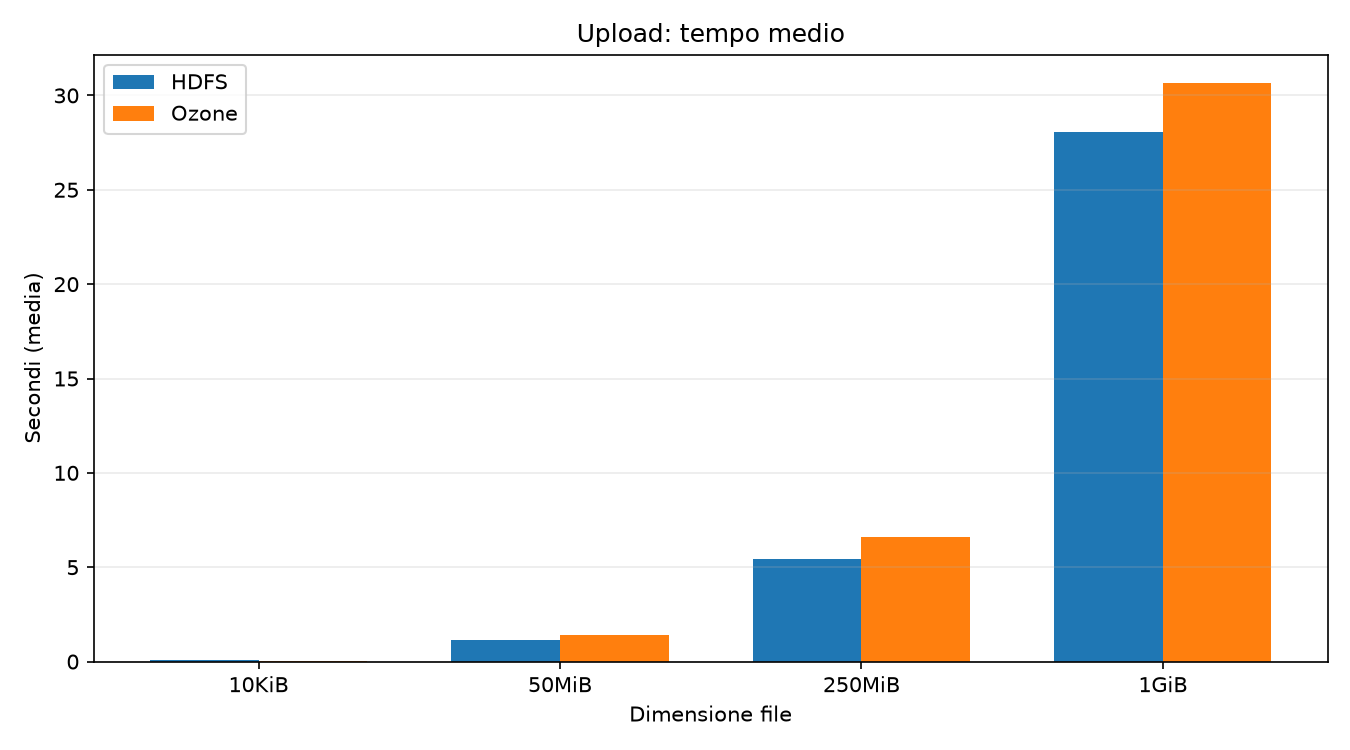

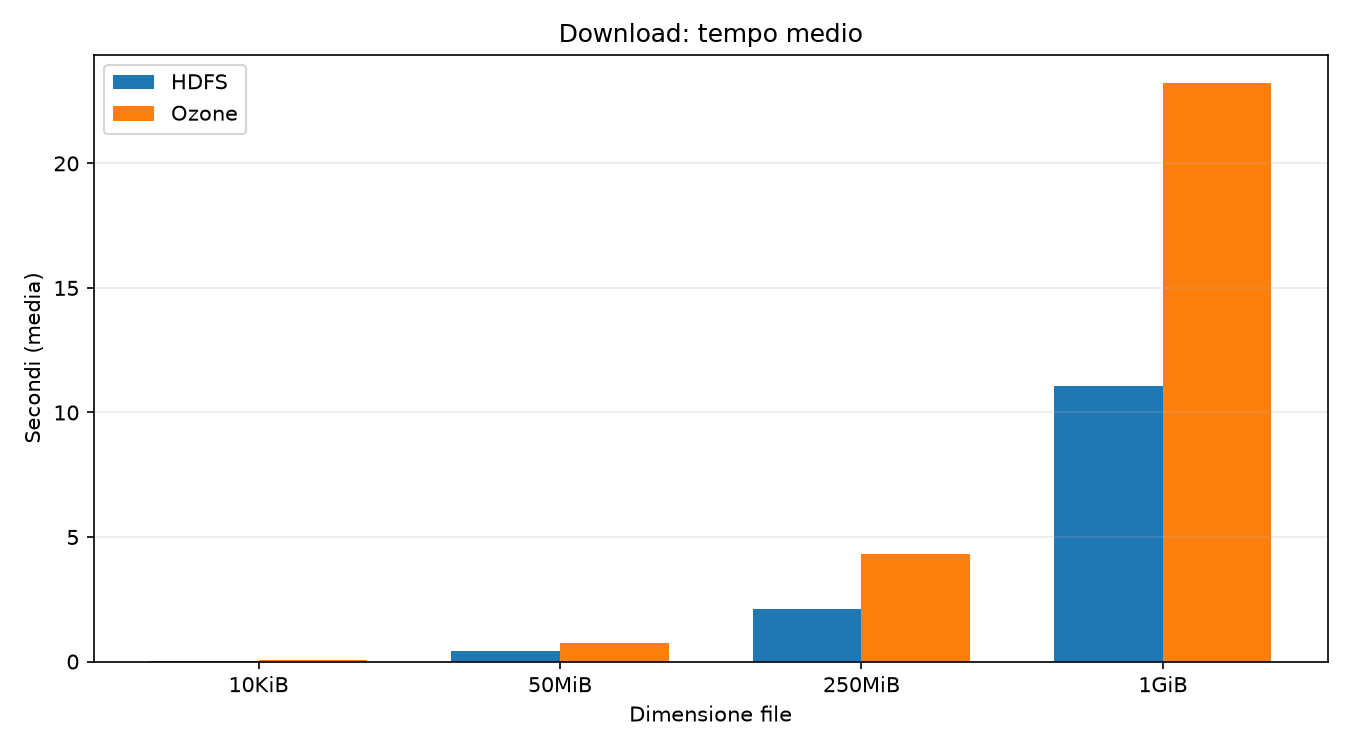

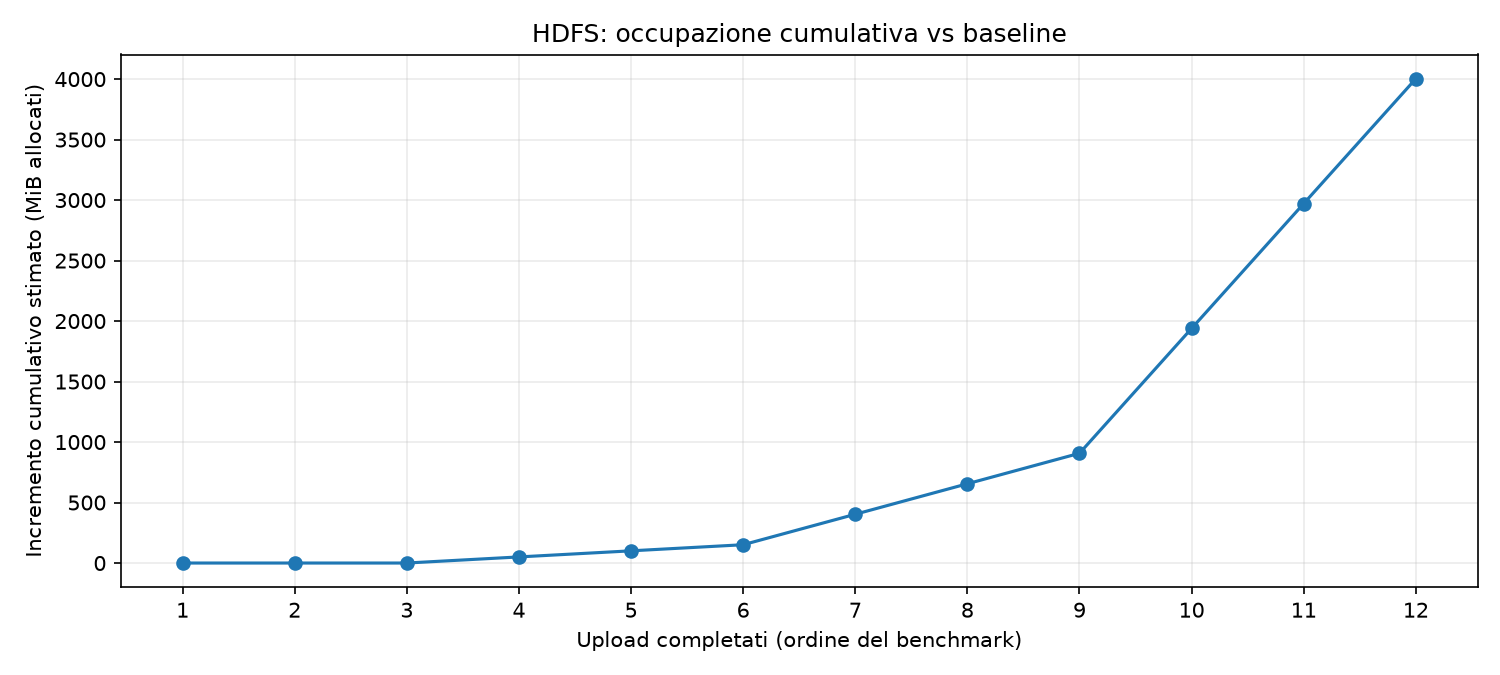

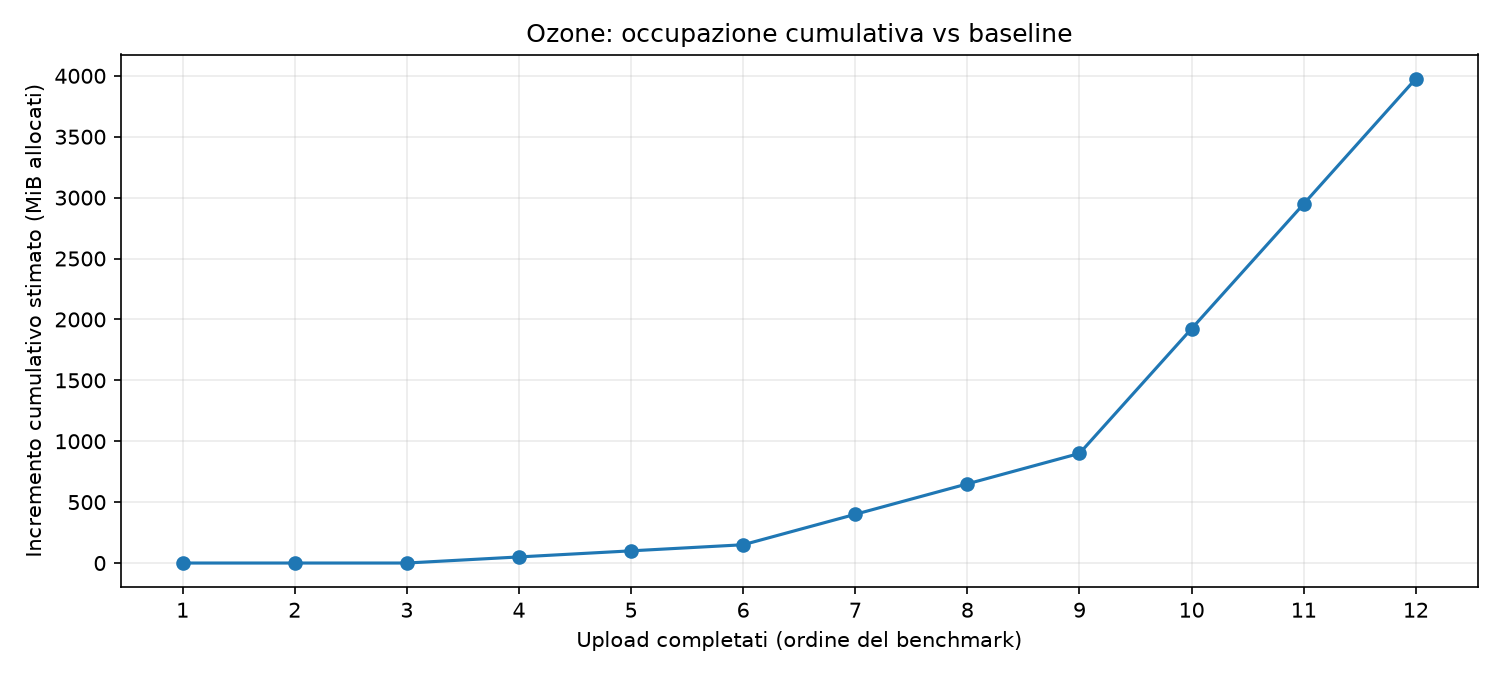

In [4]:
from IPython.display import Image, display

for grafico in risultato["plots"]:
    display(Image(filename=grafico))

## Integrità e numero di misure

In [5]:
grezzi = pd.read_csv(risultato["raw_csv"])
cicli_attesi = 4 * 2 * config.repetitions
print(f"Cicli verificati: {len(grezzi)} / {cicli_attesi}")
print("SHA-256 validi:", grezzi["verified"].all())
assert len(grezzi) == cicli_attesi, f"Attesi {cicli_attesi} cicli, trovati {len(grezzi)}"
assert grezzi["verified"].all(), "Almeno un download non ha superato la verifica SHA-256"

Cicli verificati: 24 / 24
SHA-256 validi: True


## Analisi dell’occupazione dello storage

Le seguenti metriche sono state raccolte **durante gli stessi 24 cicli**, senza nuovi upload: spazio iniziale e finale, delta dei volumi DataNode, delta dei metadati, incremento cumulativo rispetto alla baseline.

**Limiti:** si sommano i byte allocati (`st_blocks × 512`) nei file dei volumi, non i settori fisici reali. Ozone può preallocare/riutilizzare container e aggiornare metadati in modo asincrono. Il `delta` non è sempre equivalente a “dimensione file + overhead”. Le misure sono sensibili ai carichi concorrenti.

In [6]:
grezzi = pd.read_csv(risultato["raw_csv"])
colonne = ["system", "size_label", "repeat", "storage_before_bytes", "storage_after_bytes", "storage_delta_bytes", "storage_cumulative_bytes", "storage_data_delta_bytes", "storage_metadata_delta_bytes", "storage_overhead_pct"]
display(grezzi[colonne])
assert len(grezzi) == 4 * 2 * config.repetitions


,system,size_label,repeat,storage_before_bytes,storage_after_bytes,storage_delta_bytes,storage_cumulative_bytes,storage_data_delta_bytes,storage_metadata_delta_bytes,storage_overhead_pct
0,HDFS,10KiB,1,19597914112,19597930496,16384,16384,16384,0,60.000
1,Ozone,10KiB,1,20527919104,20527931392,12288,12288,12288,0,20.000
2,Ozone,10KiB,2,20527931392,20527943680,12288,24576,12288,0,20.000
3,HDFS,10KiB,2,19597930496,19597946880,16384,32768,16384,0,60.000
4,HDFS,10KiB,3,19597946880,19597963264,16384,49152,16384,0,60.000
5,Ozone,10KiB,3,20527943680,20527955968,12288,36864,12288,0,20.000
6,HDFS,50MiB,1,19597963264,19650805760,52842496,52891648,52842496,0,0.789
7,Ozone,50MiB,1,20527955968,20580384768,52428800,52465664,52428800,0,0.000
8,Ozone,50MiB,2,20580384768,20632813568,52428800,104894464,52428800,0,0.000
9,HDFS,50MiB,2,19650805760,19703648256,52842496,105734144,52842496,0,0.789


## Grafici della crescita cumulativa

I valori sono separati per HDFS e Ozone e fanno riferimento alla prima fotografia dei rispettivi volumi. Non interpretarli come capacità fisiche indipendenti del computer.

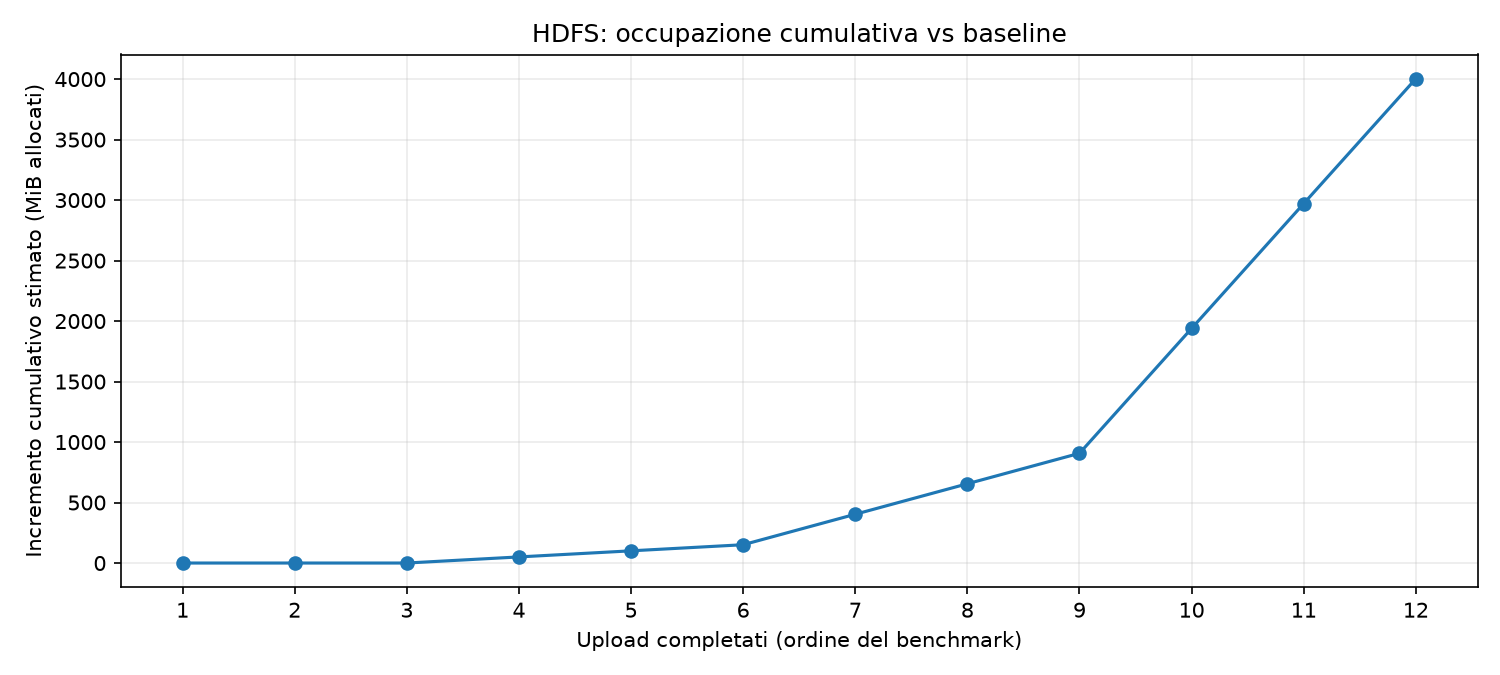

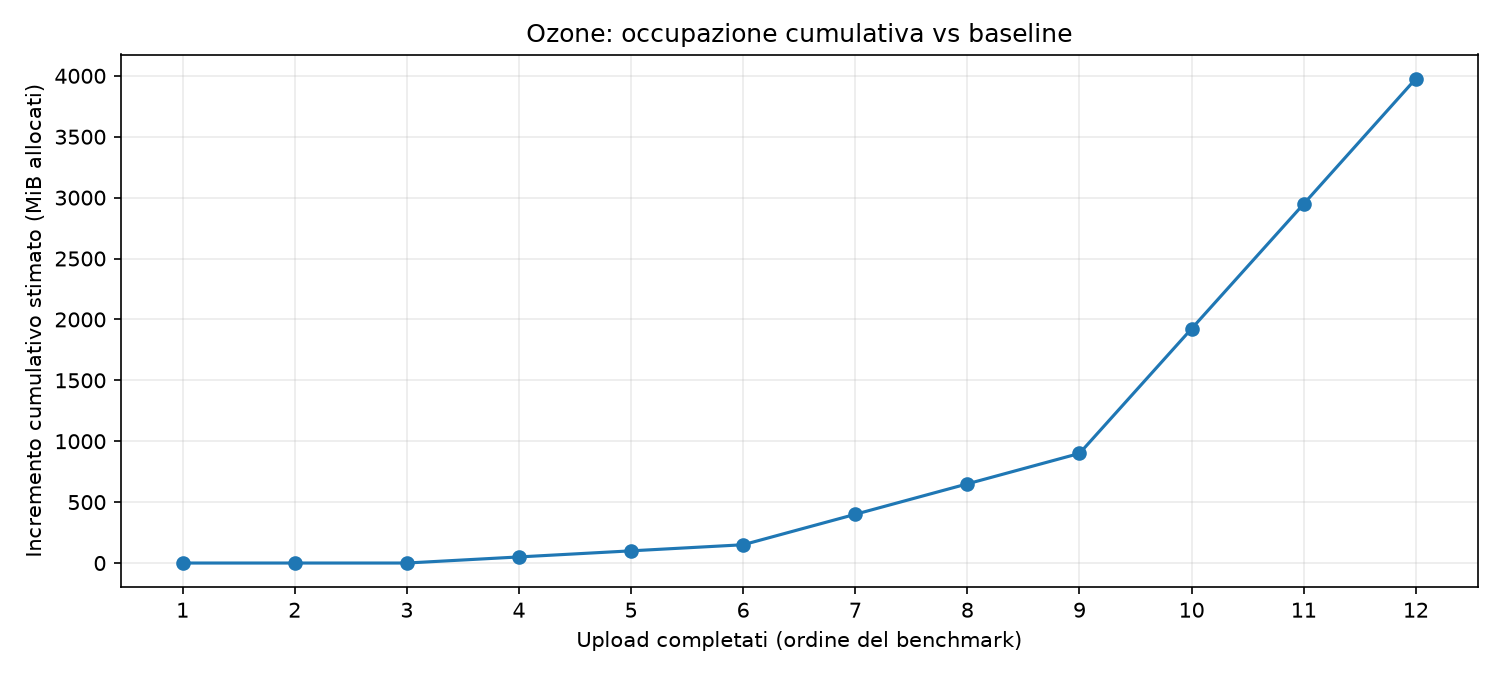

In [7]:
from IPython.display import display, Image
for percorso in plot_storage_results(risultato["run_id"], results_dir=config.results_dir):
    display(Image(filename=str(percorso)))